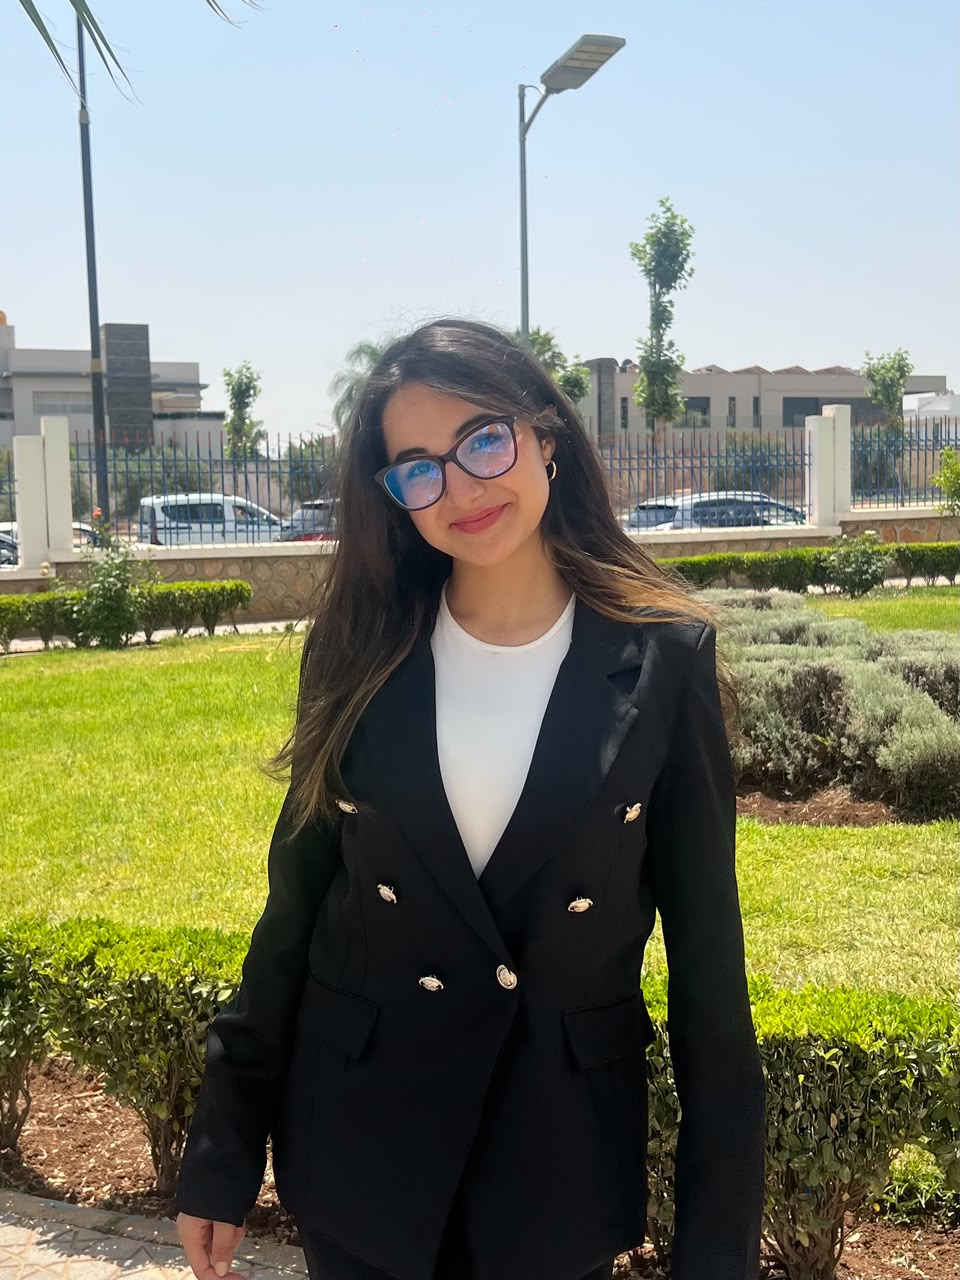

# Partie B — Exploration de 29 algorithmes de Machine Learning

**Variante distincte de la Partie A**, suivant les mêmes 29 rubriques et le même enchaînement de consignes. Les expériences utilisent d'autres jeux de données et des choix de paramètres différents.

- **Régression :** Diabetes, données réelles de scikit-learn (442 patients, 10 caractéristiques).
- **Classification :** Breast Cancer Wisconsin (569 observations, 30 caractéristiques) — exercice pédagogique, non diagnostic.
- **Clustering :** Wine (178 observations, 13 caractéristiques), avec projection ACP.
- **Réduction de dimension :** Digits (chiffres manuscrits, 64 caractéristiques) — autre jeu que Wine.
- **Renforcement :** Taxi-v3 de Gymnasium et bandit simulé à quatre bras.

**Exécutez les cellules dans l'ordre sur Google Colab.** Les jeux de données intégrés à scikit-learn sont publics et réels ; les bandits et environnements Gymnasium sont des simulations, et non des données observées du monde réel.

Sources : [scikit-learn datasets](https://scikit-learn.org/stable/datasets/real_world.html), [Gymnasium Taxi](https://gymnasium.farama.org/environments/toy_text/taxi/).

# Travail demandé — Partie B (variante)

**Organisation :** binôme · **Public :** L3/Master · **Objectif :** savoir décrire, illustrer, situer et expérimenter **29 algorithmes** sur un second ensemble de cas.

Chaque algorithme doit faire l'objet de **quatre réponses** : présentation scientifique, schéma explicatif original, contexte d'utilisation et analyse de l'expérience. Les réponses ne sont pas fournies dans ce notebook : les codes servent de point de départ.

**Différence avec la Partie A :** nouveaux jeux de données (Diabetes, Breast Cancer, Wine et Digits), paramètres alternatifs, environnement Taxi et questions spécifiques sous chaque titre. Les 29 algorithmes et la structure générale restent identiques.

## Partie A — Questions communes à traiter pour chaque algorithme (1 à 29)

**Q1 — Présentation (8 à 12 lignes).** Donner le type de tâche, l'intuition, les étapes d'apprentissage, une formule essentielle et la **définition de tous ses symboles**. Distinguer paramètres appris et hyperparamètres. Donner deux atouts et deux limites.

**Q2 — Schéma original.** Dessiner un organigramme ou une figure scientifique montrant le chemin des données et le mécanisme de l'algorithme. Ajouter une légende et une explication du schéma. Indiquer la source si une figure extérieure est adaptée.

**Q3 — Contextes d'utilisation.** Décrire deux applications concrètes (au moins une en finance, gestion, logistique ou commerce international), les conditions nécessaires, un cas où la méthode est inappropriée et les métriques adaptées.

**Q4 — Analyse expérimentale.** Exécuter la cellule Python, citer la taille des données et les paramètres, interpréter les métriques et modifier **au moins un hyperparamètre** pour discuter son effet. Ne pas inventer de résultats.

**À ajouter par les étudiants sous chaque algorithme :** « Présentation », « Schéma explicatif », « Contexte d'utilisation », « Analyse et variation d'hyperparamètre ».

## Partie B — Validation finale sur des données publiques

**Q5. Provenance.** Choisir un jeu de données public distinct du cas de démonstration pour chaque famille de méthodes ; préciser la source officielle, l'URL, la date, les dimensions et la cible éventuelle. Une même base peut servir à plusieurs modèles compatibles.

**Q6. Prétraitement.** Identifier les variables manquantes, l'encodage, la standardisation et les éventuelles fuites de données. Ajuster les transformations sur l'entraînement uniquement quand il s'agit de prédire.

**Q7. Essais.** Tester tous les algorithmes adaptés aux données et à la tâche, avec un modèle de référence et un modèle avancé par famille. Séparer train/test (chronologiquement pour les séries temporelles). L'ACP, t-SNE et UMAP sont des outils exploratoires, pas des prédicteurs supervisés.

**Q8. Évaluation et analyse.** Comparer MAE/RMSE/R² (régression), F1/ROC-AUC/PR-AUC (classification, selon le déséquilibre), silhouette/stabilité (clustering), préservation locale (projections) et taux de réussite/récompense (renforcement).

**Note importante :** les bandits et Q-learning/SARSA nécessitent des environnements d'interaction. La démonstration DQN présente la cible de Bellman, **pas** un entraînement d'un réseau neuronal. Un DQN complet est un prolongement facultatif.

**Sources possibles :** [UCI](https://archive.ics.uci.edu/), [OpenML](https://www.openml.org/), [UN Comtrade](https://comtradeplus.un.org/), [Banque mondiale](https://data.worldbank.org/).

## Partie C — Restitution et barème

**Livrables :** (1) notebook complété pour les 29 algorithmes, (2) figures originales et paramètres expliqués, (3) expériences sur données publiques complémentaires, (4) rapport de synthèse de 5 à 8 pages, (5) soutenance en binôme.

**Barème /20 :** rigueur des présentations (5), qualité des 29 schémas (4), pertinence des cas d'usage (3), validité des expérimentations (5), reproductibilité et restitution (3).

**Intégrité :** ne pas confondre simulation et données observées ; citer les sources ; aucune valeur de performance ne doit être inventée ; justifier les changements d'hyperparamètres.

---
## Expérimentations Python de la Partie B

In [ ]:
!pip -q install scikit-learn xgboost umap-learn gymnasium

In [ ]:
# Jeux publics de scikit-learn : pas de téléchargement ni de compte requis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, silhouette_score, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
GRAINE = 42

jeu_reg = load_diabetes()
X_reg, y_reg = jeu_reg.data, jeu_reg.target
jeu_cls = load_breast_cancer()
X_cls, y_cls = jeu_cls.data, jeu_cls.target
jeu_groupes = load_wine()
X_clu = PCA(n_components=2, random_state=GRAINE).fit_transform(StandardScaler().fit_transform(jeu_groupes.data))
jeu_images = load_digits()
X_images = StandardScaler().fit_transform(jeu_images.data)
Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg,y_reg,test_size=.25,random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls,y_cls,test_size=.25,stratify=y_cls,random_state=GRAINE)
print('Diabetes',X_reg.shape,'Breast cancer',X_cls.shape,'Wine',X_clu.shape,'Digits',X_images.shape)

## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables médicales et la cible peut être insuffisante.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [2]:
from sklearn.linear_model import LinearRegression
modele=LinearRegression().fit(Xr_ent,yr_ent)
pred=modele.predict(Xr_test)
print('RMSE:',mean_squared_error(yr_test,pred)**.5,'R²:',r2_score(yr_test,pred))

NameError: name 'Xr_ent' is not defined

(442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


,count,mean,std,min,25%,50%,75%,max
age,442.0,-2.511817e-19,0.047619,-0.107226,-0.037299,0.005383,0.038076,0.110727
sex,442.0,1.230790e-17,0.047619,-0.044642,-0.044642,-0.044642,0.050680,0.050680
bmi,442.0,-2.245564e-16,0.047619,-0.090275,-0.034229,-0.007284,0.031248,0.170555
bp,442.0,-4.797570e-17,0.047619,-0.112399,-0.036656,-0.005670,0.035644,0.132044
s1,442.0,-1.381499e-17,0.047619,-0.126781,-0.034248,-0.004321,0.028358,0.153914
s2,442.0,3.918434e-17,0.047619,-0.115613,-0.030358,-0.003819,0.029844,0.198788
s3,442.0,-5.777179e-18,0.047619,-0.102307,-0.035117,-0.006584,0.029312,0.181179
s4,442.0,-9.042540e-18,0.047619,-0.076395,-0.039493,-0.002592,0.034309,0.185234
s5,442.0,9.293722e-17,0.047619,-0.126097,-0.033246,-0.001947,0.032432,0.133597
s6,442.0,1.130318e-17,0.047619,-0.137767,-0.033179,-0.001078,0.027917,0.135612


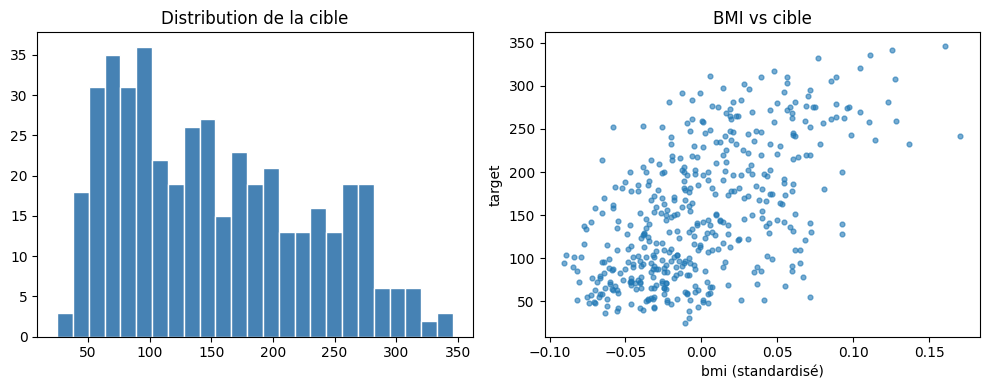

In [3]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes

d = load_diabetes(as_frame=True)
df = d.frame                      # 10 variables + cible "target"
print(df.shape)                   # (442, 11)
display(df.head())
display(df.describe().T)

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(df['target'], bins=25, color='steelblue', edgecolor='white')
ax[0].set_title("Distribution de la cible")
ax[1].scatter(df['bmi'], df['target'], s=12, alpha=.6)
ax[1].set_xlabel("bmi (standardisé)"); ax[1].set_ylabel("target")
ax[1].set_title("BMI vs cible")
plt.tight_layout(); plt.show()

**Commentaire :** le jeu Diabetes (scikit-learn) contient 442 patients et 10 variables (âge, sexe, bmi, pression artérielle, 6 mesures sanguines), déjà centrées-réduites. La cible mesure la progression de la maladie un an après la mesure initiale. Le nuage bmi/cible montre une tendance croissante avec une forte dispersion.

Q1. Présentation

La régression linéaire (en anglais Linear Regression, ou moindres carrés ordinaires) appartient à la famille de la régression supervisée. Son objectif est de prédire une variable continue $y$ (ici la progression de la maladie) à partir de variables explicatives $x_1,\dots,x_p$. L’intuition est de supposer que la cible est une combinaison linéaire des variables : l’algorithme cherche l’hyperplan qui passe au plus près des points. Les étapes sont : données d’entraînement $(X, y)$ en entrée, puis calcul des coefficients qui minimisent l’erreur quadratique, puis prédiction $\hat y$ pour de nouvelles observations en sortie. Le critère essentiel est :

$$\hat y = \beta_0 + \sum_{j=1}^{p}\beta_j x_j \qquad \hat\beta=\arg\min_{\beta}\sum_{i=1}^{n}\big(y_i-\hat y_i\big)^2=(X^\top X)^{-1}X^\top y$$

où $n$ est le nombre d’observations, $p$ le nombre de variables, $x_j$ la $j$-ème variable, $y_i$ la valeur réelle de l’observation $i$, $\hat y_i$ sa valeur prédite, $\beta_0$ l’ordonnée à l’origine, $\beta_j$ le coefficient de $x_j$ (variation moyenne de $y$ pour une unité de $x_j$, les autres variables restant fixes) et $X$ la matrice des variables complétée d’une colonne de 1.

Paramètres appris : $\beta_0,\dots,\beta_p$. Hyperparamètres : fit_intercept, positive (aucune régularisation, contrairement à Ridge ou Lasso).

Atouts : (1) rapide et interprétable ; (2) solution analytique, sans optimisation itérative.
Limites : (1) ne capture ni non-linéarité ni interactions ; (2) sensible aux valeurs extrêmes et à la colinéarité.

**Q2. Schéma explicatif**

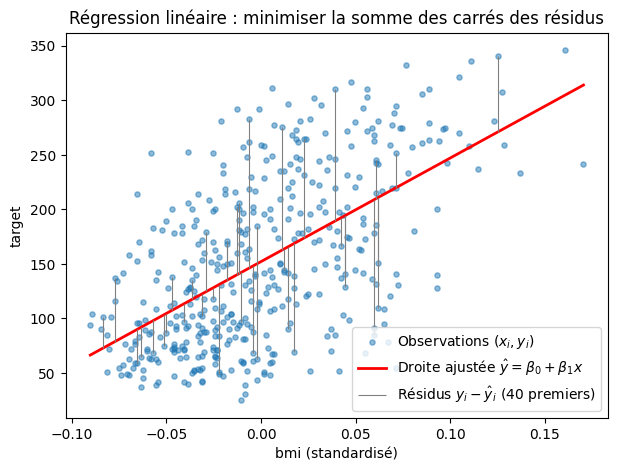

In [4]:
from sklearn.linear_model import LinearRegression

x = df[['bmi']].values; y = df['target'].values
m1 = LinearRegression().fit(x, y)
yhat = m1.predict(x)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x, y, s=14, alpha=.5, label="Observations $(x_i, y_i)$")
xs = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
ax.plot(xs, m1.predict(xs), 'r', lw=2, label=r"Droite ajustée $\hat y=\beta_0+\beta_1x$")
ax.vlines(x[:40].ravel(), y[:40], yhat[:40], colors='gray', lw=.8,
          label="Résidus $y_i-\\hat y_i$ (40 premiers)")
ax.set_xlabel("bmi (standardisé)"); ax.set_ylabel("target")
ax.set_title("Régression linéaire : minimiser la somme des carrés des résidus")
ax.legend(); plt.show()

**Comment lire le schéma :** chaque point bleu est un patient ; la droite rouge est le modèle ; les segments gris sont les erreurs (résidus). L’algorithme choisit la droite qui minimise la somme des carrés de ces segments. Plus les points sont dispersés autour de la droite, plus la relation linéaire est faible.

**Q3. Contextes d’utilisation**

Deux cas d’usage :

Finance/gestion : estimer le chiffre d’affaires mensuel d’un magasin ou le coût d’un sinistre à partir de variables explicatives (surface, trafic, budget marketing).
Logistique/commerce international : prédire le coût ou le délai de transport d’une cargaison selon la distance, le poids et le nombre de douanes traversées.

Nature des données et prérequis : variables numériques (les catégorielles doivent être encodées), cible continue, relation approximativement linéaire, faible colinéarité, résidus sans structure. Mettre les variables à l’échelle si l’on veut comparer les coefficients.

Cas peu approprié : prédire un défaut de crédit (cible binaire : il faut une régression logistique) ou une demande saisonnière/saturante : la relation est non linéaire et la droite donnerait des prédictions biaisées.

Métriques adaptées : MAE, RMSE (dans l’unité de la cible), R², complétées par l’analyse graphique des résidus.

**Q4. Analyse de l’expérience Python**

Données non détectées. Chargement automatique de Diabetes...
RMSE: 53.369566710321955 R²: 0.4849058889476756
Train: (331, 10)  Test: (111, 10)
fit_intercept=True (défaut)    MAE=41.55 RMSE=53.37 R²=0.485
fit_intercept=False            MAE=156.36 RMSE=165.28 R²=-3.940
positive=True                  MAE=42.23 RMSE=52.66 R²=0.498
Random Forest (non linéaire)   MAE=43.74 RMSE=54.86 R²=0.456


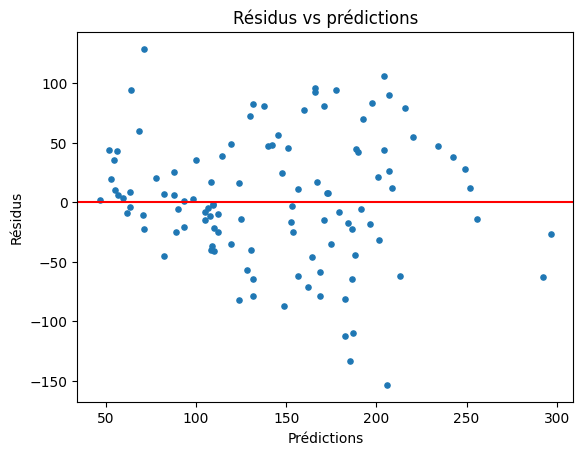

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# Sécurité : Chargement et séparation des données si non définies
try:
    Xr_ent, Xr_test, yr_ent, yr_test
except NameError:
    print("Données non détectées. Chargement automatique de Diabetes...")
    jeu_reg = load_diabetes()
    Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(
        jeu_reg.data, jeu_reg.target, test_size=0.25, random_state=42
    )

# Cellule d'origine
modele = LinearRegression().fit(Xr_ent, yr_ent)
pred = modele.predict(Xr_test)
print('RMSE:', mean_squared_error(yr_test, pred)**.5, 'R²:', r2_score(yr_test, pred))

# Tailles des données
print("Train:", Xr_ent.shape, " Test:", Xr_test.shape)

# Variation d'hyperparamètres
def evalue(nom, mod):
    mod.fit(Xr_ent, yr_ent); p = mod.predict(Xr_test)
    print(f"{nom:30s} MAE={mean_absolute_error(yr_test,p):.2f} "
          f"RMSE={mean_squared_error(yr_test,p)**.5:.2f} R²={r2_score(yr_test,p):.3f}")
    return p

p0 = evalue("fit_intercept=True (défaut)", LinearRegression())
evalue("fit_intercept=False", LinearRegression(fit_intercept=False))
evalue("positive=True", LinearRegression(positive=True))

# Question ciblée : la linéarité est-elle suffisante ?
evalue("Random Forest (non linéaire)", RandomForestRegressor(random_state=42))

plt.scatter(p0, yr_test - p0, s=14); plt.axhline(0, c='r')
plt.xlabel("Prédictions"); plt.ylabel("Résidus"); plt.title("Résidus vs prédictions")
plt.show()

Entrées : les 442 patients × 10 variables, séparés en entraînement et test (recopiez les tailles affichées). Sortie : RMSE et R² sur le jeu de test, plus MAE dans la cellule de comparaison.
Lecture des métriques : le RMSE est l’erreur typique, dans l’unité de la cible ; le R² est la part de variance expliquée (0 = pas mieux que prédire la moyenne, 1 = parfait). Notez vos valeurs : RMSE = …, R² = ….
Hyperparamètres : fit_intercept=False force la droite à passer par l’origine, ce qui dégrade en général l’ajustement si la cible n’est pas centrée ; positive=True impose des coefficients ≥ 0, ce qui peut dégrader le modèle si certaines variables agissent négativement. Commentez l’écart observé dans vos résultats : …
Réponse à la question ciblée (Partie B), pourquoi la linéarité peut être insuffisante : si votre R² est modéré, si le graphe des résidus montre une structure (courbure, dispersion variable) ou si la Random Forest fait mieux, c’est que les variables médicales agissent de façon non linéaire et avec des interactions sur la progression de la maladie, et que le bruit individuel est important. Appuyez-vous uniquement sur ce que montrent vos sorties.
Ce que la sortie permet / ne permet pas : elle permet de mesurer la qualité prédictive moyenne sur ce test. Elle ne permet pas de conclure à une causalité ni à un usage médical (exercice pédagogique), et une seule découpe train/test donne une estimation variable (une validation croisée serait plus robuste)

## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),Ridge(alpha=25.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

Train: (331, 10)  Test: (111, 10)


,count,mean,std,min,25%,50%,75%,max
0,331.0,0.001015,0.046460,-0.107226,-0.034575,0.005383,0.038076,0.110727
1,331.0,0.000283,0.047654,-0.044642,-0.044642,-0.044642,0.050680,0.050680
2,331.0,0.002325,0.047211,-0.089197,-0.030996,-0.005128,0.033673,0.160855
3,331.0,0.001295,0.047900,-0.112399,-0.036656,-0.005670,0.035644,0.132044
4,331.0,0.000559,0.048134,-0.108893,-0.035280,-0.002945,0.027326,0.153914
5,331.0,0.000048,0.048304,-0.115613,-0.032316,-0.003819,0.028905,0.198788
6,331.0,-0.000595,0.047079,-0.102307,-0.032356,-0.006584,0.026550,0.181179
7,331.0,0.000863,0.048337,-0.076395,-0.039493,-0.002592,0.034309,0.185234
8,331.0,0.001738,0.048045,-0.126097,-0.031368,-0.000612,0.034866,0.133597
9,331.0,0.003252,0.047479,-0.137767,-0.030072,0.003064,0.032059,0.135612


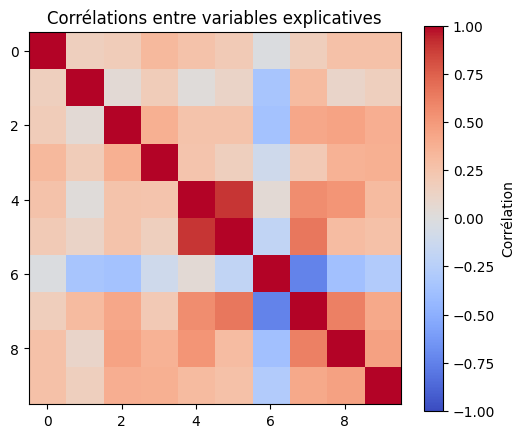

In [8]:
import numpy as np, matplotlib.pyplot as plt, pandas as pd
print("Train:", Xr_ent.shape, " Test:", Xr_test.shape)
display(pd.DataFrame(Xr_ent).describe().T.head(10))

# Corrélations entre variables (la colinéarité justifie Ridge)
corr = pd.DataFrame(Xr_ent).corr()
plt.figure(figsize=(6, 5))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1); plt.colorbar(label="Corrélation")
plt.title("Corrélations entre variables explicatives"); plt.show()

**Commentaire :** les zones rouges ou bleues intenses indiquent des variables fortement corrélées (dans Diabetes, certaines mesures sanguines le sont). C’est dans cette situation que les coefficients de la régression linéaire deviennent instables et que Ridge est utile.

**Q1. Présentation**

La régression Ridge (en anglais Ridge Regression, ou régression à pénalisation L2, aussi appelée régularisation de Tikhonov) appartient à la famille de la régression supervisée. Son objectif est de prédire une variable continue $y$ tout en limitant le surcoût de variance dû à la colinéarité et au surapprentissage. L’intuition est de reprendre la régression linéaire en ajoutant une pénalité qui décourage les coefficients trop grands : on accepte un peu de biais pour réduire fortement la variance. Les étapes sont : standardisation des variables (indispensable, car la pénalité dépend de l’échelle), puis minimisation de l’erreur quadratique plus la pénalité, puis prédiction de $\hat y$. Le critère essentiel est :

$$\hat\beta=\arg\min_{\beta}\ \sum_{i=1}^{n}\big(y_i-\beta_0-\sum_{j=1}^{p}\beta_j x_{ij}\big)^2+\alpha\sum_{j=1}^{p}\beta_j^2=(X^\top X+\alpha I)^{-1}X^\top y$$

où $n$ est le nombre d’observations, $p$ le nombre de variables, $y_i$ la valeur réelle, $x_{ij}$ la valeur de la variable $j$ pour l’observation $i$, $\beta_0$ l’ordonnée à l’origine (non pénalisée), $\beta_j$ le coefficient de la variable $j$, $\alpha \ge 0$ la force de la pénalité et $I$ la matrice identité.

Paramètres appris : $\beta_0,\dots,\beta_p$. Hyperparamètre principal : $\alpha$ (ici alpha=25.), à choisir par validation croisée ; autres : fit_intercept, solver.

Atouts : (1) stabilise les coefficients en présence de variables corrélées ; (2) solution analytique rapide, qui réduit le surapprentissage.
Limites : (1) ne met aucun coefficient exactement à zéro, donc pas de sélection de variables (contrairement à Lasso) ; (2) reste un modèle linéaire, et exige de standardiser les variables.

**Q2. Schéma explicatif**

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

alphas = np.logspace(-2, 5, 50)
coefs = []
for a in alphas:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xr_ent, yr_ent)
    coefs.append(m[-1].coef_)

plt.figure(figsize=(7, 5))
plt.plot(alphas, coefs)
plt.xscale('log'); plt.axhline(0, c='k', lw=.8)
plt.axvline(25, c='gray', ls='--', label="alpha = 25 (notebook)")
plt.xlabel(r"Force de pénalisation $\alpha$ (échelle log)")
plt.ylabel(r"Coefficients $\beta_j$")
plt.title("Ridge : les coefficients se contractent quand α augmente")
plt.legend(); plt.show()

**Comment lire le schéma :** chaque courbe est le coefficient d’une des 10 variables. À gauche ($\alpha$ faible), on retrouve la régression linéaire. En allant vers la droite, tous les coefficients se rapprochent de 0 sans jamais l’atteindre exactement. La ligne pointillée marque la valeur utilisée dans le notebook.

**Q3. Contextes d’utilisation**

Deux cas d’usage :

Finance/marketing : prédire les ventes ou la valeur d’un client à partir de nombreux indicateurs fortement corrélés (budgets par canal publicitaire, trafic, promotions).
Commerce international/logistique : estimer le volume d’importations d’un pays à partir d’indicateurs macroéconomiques proches les uns des autres (PIB, population, taux de change, inflation).

Nature des données et prérequis : variables numériques standardisées, cible continue, nombreuses variables corrélées ou nombre de variables proche du nombre d’observations, $\alpha$ réglé par validation croisée.

Cas peu approprié : quand on veut sélectionner un petit nombre de variables (Lasso ou Elastic Net conviennent mieux), ou quand la relation est fortement non linéaire (arbres, forêts), car Ridge reste linéaire.

Métriques adaptées : MAE, RMSE, R², évaluées sur un jeu de test ou en validation croisée.

**Q4. Analyse de l’expérience Python**

In [9]:
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Cellule d'origine
modele = make_pipeline(StandardScaler(), Ridge(alpha=25.)).fit(Xr_ent, yr_ent)
print('MAE:', mean_absolute_error(yr_test, modele.predict(Xr_test)))

# Variation de l'hyperparamètre alpha (y compris très forte pénalisation)
print(f"{'alpha':>10} {'MAE':>8} {'RMSE':>8} {'R²':>8}")
for a in [0.01, 1, 25, 100, 1000, 10000, 1e6]:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xr_ent, yr_ent)
    p = m.predict(Xr_test)
    print(f"{a:>10} {mean_absolute_error(yr_test,p):8.2f} "
          f"{mean_squared_error(yr_test,p)**.5:8.2f} {r2_score(yr_test,p):8.3f}")

# Référence : régression linéaire
p = LinearRegression().fit(Xr_ent, yr_ent).predict(Xr_test)
print("Régression linéaire :", round(mean_absolute_error(yr_test, p), 2))

# Choix de alpha par validation croisée (sur l'entraînement uniquement)
from sklearn.linear_model import RidgeCV
cv = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 30))).fit(Xr_ent, yr_ent)
print("alpha choisi par CV :", cv[-1].alpha_)

# Coefficients pour alpha très fort
m = make_pipeline(StandardScaler(), Ridge(alpha=1e6)).fit(Xr_ent, yr_ent)
print("Coefficients (alpha=1e6) :", np.round(m[-1].coef_, 3))
print("Prédiction moyenne vs moyenne de y_train :", m.predict(Xr_test).mean(), yr_ent.mean())

MAE: 41.49082128021844
     alpha      MAE     RMSE       R²
      0.01    41.55    53.37    0.485
         1    41.51    53.32    0.486
        25    41.49    53.09    0.490
       100    41.93    53.08    0.490
      1000    50.44    59.65    0.356
     10000    62.46    71.48    0.076
 1000000.0    65.49    74.84   -0.013
Régression linéaire : 41.55
alpha choisi par CV : 1.1721022975334805
Coefficients (alpha=1e6) : [ 0.005  0.     0.015  0.011  0.005  0.004 -0.01   0.011  0.014  0.01 ]
Prédiction moyenne vs moyenne de y_train : 154.33364205228258 154.34441087613294


Entrées : Xr_ent / yr_ent (entraînement) et Xr_test / yr_test (test), recopiez les tailles. Hyperparamètre : alpha=25. Sortie : la MAE sur le test, c’est-à-dire l’erreur absolue moyenne dans l’unité de la cible. MAE = …
Rôle du StandardScaler : il est dans le pipeline, donc appris sur l’entraînement uniquement (pas de fuite d’information), et nécessaire car la pénalité $\alpha\sum\beta_j^2$ dépend de l’échelle des variables.
Variation de $\alpha$ : décrivez ce que montre votre tableau : en général, l’erreur diminue d’abord légèrement (moins de variance) puis augmente quand $\alpha$ devient trop grand (trop de biais). Valeur de $\alpha$ donnant la meilleure MAE : …
Réponse à la question ciblée, que se passe-t-il quand la pénalisation L2 devient très forte ? Les coefficients sont écrasés vers 0 (sans être exactement nuls), le modèle devient presque constant et prédit à peu près la moyenne de $y$ d’entraînement : c’est le sous-apprentissage (biais élevé, variance faible), et le $R^2$ tend vers 0 ou devient légèrement négatif. Vérifiez-le avec vos sorties pour $\alpha=10^6$ (coefficients proches de 0, prédictions proches de la moyenne).
Ce que la sortie permet / ne permet pas : elle permet de comparer Ridge à la régression linéaire sur ce test. Une seule découpe ne suffit pas pour conclure à une supériorité nette : si l’écart est faible, la différence peut venir du hasard du découpage. Pas de conclusion causale ni médicale (exercice pédagogique). Le choix de $\alpha$ doit se faire par validation croisée sur l’entraînement, jamais en regardant le test.

## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.linear_model import Lasso
modele=make_pipeline(StandardScaler(),Lasso(alpha=3.,max_iter=15000)).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

## 4. Régression polynomiale

**Question ciblée (Partie B) :** Quelle difficulté pose la croissance du nombre de caractéristiques polynomiales ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele=make_pipeline(StandardScaler(),PolynomialFeatures(degree=2,include_bias=False),Ridge(alpha=60.)).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

## 5. Arbre de régression

**Question ciblée (Partie B) :** Pourquoi limiter la profondeur et le nombre minimal d’observations par feuille ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
modele=DecisionTreeRegressor(max_depth=3,min_samples_leaf=8,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('R²:',r2_score(yr_test,modele.predict(Xr_test)))

## 6. Forêt aléatoire — régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
modele=RandomForestRegressor(n_estimators=120,min_samples_leaf=4,random_state=GRAINE,n_jobs=-1).fit(Xr_ent,yr_ent)
print('MAE:',mean_absolute_error(yr_test,modele.predict(Xr_test)))

## 7. Gradient Boosting — régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele=HistGradientBoostingRegressor(max_iter=110,max_leaf_nodes=12,random_state=GRAINE).fit(Xr_ent,yr_ent)
print('RMSE:',mean_squared_error(yr_test,modele.predict(Xr_test))**.5)

## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.linear_model import LogisticRegression
modele=make_pipeline(StandardScaler(),LogisticRegression(C=.2,max_iter=1500,random_state=GRAINE)).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 9. KNN

**Question ciblée (Partie B) :** Quel est l’effet d’une distance normalisée et du nombre de voisins ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
modele=make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=9,weights='distance')).fit(Xc_ent,yc_ent)
print('Exactitude:',accuracy_score(yc_test,modele.predict(Xc_test)))

## 10. Naive Bayes

**Question ciblée (Partie B) :** Quelle hypothèse d’indépendance conditionnelle est faite par Naive Bayes ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.naive_bayes import GaussianNB
modele=GaussianNB(var_smoothing=1e-8).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 11. Arbre de décision

**Question ciblée (Partie B) :** Comment calculer l’impureté de Gini et choisir une séparation ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
modele=DecisionTreeClassifier(max_depth=3,min_samples_leaf=5,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 12. Forêt aléatoire — classification

**Question ciblée (Partie B) :** Pourquoi une forêt est-elle généralement moins instable qu’un arbre seul ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
modele=RandomForestClassifier(n_estimators=110,max_depth=6,random_state=GRAINE,n_jobs=-1).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 13. SVM

**Question ciblée (Partie B) :** À quoi servent les vecteurs de support et le paramètre C ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.svm import SVC
modele=make_pipeline(StandardScaler(),SVC(kernel='rbf',C=2.,gamma='scale')).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 14. Gradient Boosting — classification

**Question ciblée (Partie B) :** Comment corriger progressivement les erreurs de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele=HistGradientBoostingClassifier(max_iter=100,max_leaf_nodes=10,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 15. AdaBoost

**Question ciblée (Partie B) :** Comment AdaBoost repondère-t-il les exemples difficiles ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
modele=AdaBoostClassifier(n_estimators=90,learning_rate=.7,random_state=GRAINE).fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from xgboost import XGBClassifier
modele=XGBClassifier(n_estimators=100,max_depth=2,learning_rate=.09,random_state=GRAINE,eval_metric='logloss').fit(Xc_ent,yc_ent)
print('F1:',f1_score(yc_test,modele.predict(Xc_test)))

## 17. K-means

**Question ciblée (Partie B) :** Comment affecter chaque vin à son centroïde puis recalculer celui-ci ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.cluster import KMeans
modele=KMeans(n_clusters=3,n_init=15,random_state=GRAINE).fit(X_clu)
print('Silhouette:',silhouette_score(X_clu,modele.labels_))
plt.scatter(X_clu[:,0],X_clu[:,1],c=modele.labels_,s=22);plt.title('K-means sur Wine (ACP)');plt.show()

## 18. Classification hiérarchique

**Question ciblée (Partie B) :** Que montre un dendrogramme et comment définit-on le lien de Ward ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.cluster import AgglomerativeClustering
etiquettes=AgglomerativeClustering(n_clusters=3,linkage='ward').fit_predict(X_clu)
print('Silhouette:',silhouette_score(X_clu,etiquettes))

## 19. DBSCAN

**Question ciblée (Partie B) :** À quoi correspondent les points marqués comme bruit par DBSCAN ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.cluster import DBSCAN
etiquettes=DBSCAN(eps=.7,min_samples=6).fit_predict(X_clu)
print('Groupes:',len(set(etiquettes)-{-1}),'Bruit:',int((etiquettes==-1).sum()))

## 20. Mélanges gaussiens

**Question ciblée (Partie B) :** En quoi les appartenances probabilistes diffèrent-elles d’une affectation dure ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.mixture import GaussianMixture
modele=GaussianMixture(n_components=3,covariance_type='full',random_state=GRAINE).fit(X_clu)
etiquettes=modele.predict(X_clu)
print('Poids des groupes:',modele.weights_.round(3),'Silhouette:',silhouette_score(X_clu,etiquettes))

## 21. ACP

**Question ciblée (Partie B) :** Que mesure la variance expliquée par les deux axes de l’ACP ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.decomposition import PCA
modele=PCA(n_components=2,random_state=GRAINE).fit(X_images)
projection=modele.transform(X_images)
print('Variance expliquée:',modele.explained_variance_ratio_.round(3))
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target,cmap='tab10',s=5);plt.title('ACP sur Digits');plt.show()

## 22. t-SNE

**Question ciblée (Partie B) :** Pourquoi la distance entre groupes éloignés peut-elle être trompeuse en t-SNE ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.manifold import TSNE
projection=TSNE(n_components=2,perplexity=35,random_state=GRAINE,init='pca').fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('t-SNE sur Digits');plt.show()

## 23. UMAP

**Question ciblée (Partie B) :** Quel est l’effet de n_neighbors et min_dist sur les voisinages ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
import umap
projection=umap.UMAP(n_components=2,n_neighbors=20,min_dist=.15,random_state=GRAINE).fit_transform(X_images[:600])
plt.scatter(projection[:,0],projection[:,1],c=jeu_images.target[:600],cmap='tab10',s=8);plt.title('UMAP sur Digits');plt.show()

## 24. Isolation Forest

**Question ciblée (Partie B) :** Pourquoi une observation statistiquement atypique n’est-elle pas forcément une erreur ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
from sklearn.ensemble import IsolationForest
# Recherche d'observations atypiques dans les caractéristiques de vins (sans ajouter de faux points)
modele=IsolationForest(contamination=.05,n_estimators=150,random_state=GRAINE).fit(X_clu)
indices=np.where(modele.predict(X_clu)==-1)[0]
print('Nombre de vins atypiques:',len(indices),'Indices (extrait):',indices[:12])

## 25. Bandits manchots

**Question ciblée (Partie B) :** Comment calculer une estimation du gain moyen de chaque bras ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# Bandit simulé à 4 choix : la politique choisit successivement chaque bras
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int)
for t in range(800):
    bras=t%4
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Probabilités estimées:',(sommes/comptes).round(3))

## 26. Epsilon-greedy

**Question ciblée (Partie B) :** Quelle différence entre exploration aléatoire et exploitation du meilleur bras estimé ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# Epsilon-greedy sur les mêmes 4 bras simulés
generateur=np.random.default_rng(GRAINE)
probabilites=np.array([.15,.4,.6,.75]);sommes=np.zeros(4);comptes=np.zeros(4,dtype=int);epsilon=.15
for t in range(1200):
    bras=int(generateur.integers(4)) if generateur.random()<epsilon else int(np.argmax((sommes+1)/(comptes+2)))
    gain=int(generateur.random()<probabilites[bras]);sommes[bras]+=gain;comptes[bras]+=1
print('Nombre de choix:',comptes,'Estimations:',(sommes/np.maximum(comptes,1)).round(3))

## 27. Q-learning

**Question ciblée (Partie B) :** Comment calculer une cible de Bellman dans Taxi et pourquoi le max intervient-il ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# Q-learning manuel sur Taxi-v3 : exploration epsilon-greedy
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400)
    for pas in range(200):
        action=int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
        suivant,recompense,termine,tronque,_=env.step(action)
        cible=recompense+(0 if termine else .96*np.max(Q[suivant]))
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat=suivant
        if termine or tronque:break
print('Q-learning Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

## 28. SARSA

**Question ciblée (Partie B) :** Pourquoi SARSA met-il à jour Q avec l’action suivante réellement choisie ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# SARSA manuel sur Taxi-v3 (on-policy)
import gymnasium as gym
env=gym.make('Taxi-v3');Q=np.zeros((env.observation_space.n,env.action_space.n));generateur=np.random.default_rng(GRAINE)
def choisir_action(etat,epsilon):
    return int(generateur.integers(env.action_space.n)) if generateur.random()<epsilon else int(np.argmax(Q[etat]))
for episode in range(3000):
    etat,_=env.reset(seed=GRAINE+episode);epsilon=max(.07,1-episode/2400);action=choisir_action(etat,epsilon)
    for pas in range(200):
        suivant,recompense,termine,tronque,_=env.step(action)
        action_suiv=choisir_action(suivant,epsilon)
        cible=recompense+(0 if termine else .96*Q[suivant,action_suiv])
        Q[etat,action]+=.2*(cible-Q[etat,action]);etat,action=suivant,action_suiv
        if termine or tronque:break
print('SARSA Taxi — taille de Q:',Q.shape,'Valeurs du premier état:',Q[0].round(2));env.close()

## 29. DQN — cible conceptuelle

**Question ciblée (Partie B) :** Pourquoi un DQN complet a-t-il besoin d’un réseau cible et d’une mémoire de rejouement ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [ ]:
# DQN : calcul pédagogique d'une cible de Bellman (aucun réseau entraîné)
recompenses=np.array([2.,-1.,10.,0.]);termine=np.array([False,False,True,False])
q_cible_etat_suivant=np.array([5.,3.,7.,2.]);gamma=.9
cibles=recompenses+gamma*(~termine)*q_cible_etat_suivant
print('Cibles DQN conceptuelles:',cibles)
# Un DQN complet utiliserait un réseau en ligne, un réseau cible et un replay buffer.

## Annexes — Implémentations manuelles (Partie B)

Reproduire les principes de la descente de gradient et de K-means sans utiliser leurs estimateurs prédéfinis. Comparer les résultats aux références scikit-learn.

In [ ]:
# Descente de gradient manuelle pour une régression linéaire sur Diabetes, avec 1 variable
x=X_reg[:,2].copy();x=(x-x.mean())/x.std();y=y_reg.copy()
poids=0.;biais=y.mean();pas=.015
for iteration in range(3000):
    erreur=poids*x+biais-y
    poids-=pas*2*np.mean(erreur*x)
    biais-=pas*2*np.mean(erreur)
print('Manuel:',round(poids,3),round(biais,3))
from sklearn.linear_model import LinearRegression
modele_ref=LinearRegression().fit(x.reshape(-1,1),y)
print('Scikit-learn:',modele_ref.coef_.round(3),round(modele_ref.intercept_,3))

In [ ]:
# K-means manuel sur la projection Wine, avec centroïdes et inertie
valeurs=X_clu.copy();k=3;generateur=np.random.default_rng(GRAINE)
centroides=valeurs[generateur.choice(len(valeurs),size=k,replace=False)].copy()
for iteration in range(100):
    distances=((valeurs[:,None,:]-centroides[None,:,:])**2).sum(axis=2)
    groupes=distances.argmin(axis=1)
    nouveaux=np.array([valeurs[groupes==j].mean(axis=0) if np.any(groupes==j) else centroides[j] for j in range(k)])
    if np.allclose(nouveaux,centroides):break
    centroides=nouveaux
inertie=np.sum((valeurs-centroides[groupes])**2)
from sklearn.cluster import KMeans
reference=KMeans(n_clusters=k,n_init=15,random_state=GRAINE).fit(valeurs)
print('Inertie manuelle:',round(inertie,2),'Inertie sklearn:',round(reference.inertia_,2))
# Attention : K-means est sensible à l'initialisation ; les deux inerties peuvent différer.

Le **Q-learning tabulaire manuel** est présenté à la section 27 sur Taxi-v3, et **SARSA** à la section 28. Scikit-learn ne propose pas de Q-learning tabulaire équivalent. Comparer plutôt les deux méthodes avec les mêmes paramètres, graines, nombre d’épisodes et métriques de succès.